# Midterm — Predicción de alerta de desnutrición infantil

**Maestría en Ciencia de Datos — Fundamentos de Inteligencia Artificial**

## Objetivo
Predecir `alerta_desnutricion` a partir de seis variables.

**Métrica oficial: Accuracy.**

Se evalúan modelos simples y de ensamble, se analiza el desbalance
y se genera una predicción reproducible para Kaggle.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score, roc_auc_score, recall_score,
    f1_score, confusion_matrix, balanced_accuracy_score
)

DATA = Path("data/ii_sem2026")
OUTPUT = Path("outputs")
OUTPUT.mkdir(exist_ok=True)

X = pd.read_csv(DATA / "X_train_Kaggle.csv")
y = pd.read_csv(DATA / "y_train_Kaggle.csv")["alerta_desnutricion"]
X_test = pd.read_csv(DATA / "X_test_Kaggle.csv")
sample = pd.read_csv(DATA / "sample_submission_malnutrition.csv")

assert len(X) == len(y) == 70000
assert len(X_test) == len(sample) == 30000
assert list(X.columns) == list(X_test.columns)

print("Train:", X.shape, "Test:", X_test.shape)
print("Distribucion objetivo:")
print(y.value_counts(normalize=True).round(4))


Train: (70000, 6) Test: (30000, 6)
Distribucion objetivo:
alerta_desnutricion
0    0.8999
1    0.1001
Name: proportion, dtype: float64


## 1. Análisis exploratorio

El conjunto tiene un desbalance cercano a 90/10.
Por ello se compara cada modelo contra un clasificador
que predice siempre la clase mayoritaria.


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
edad_meses,70000.0,NaN,NaN,NaN,11.459457,8.252734,-12.0,5.0,11.0,18.0,29.0
sexo,70000,2,F,35185,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,70000,4,Amazonía,17606,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nivel_educacion_madre,70000,4,Secundaria,31488,NaN,NaN,NaN,NaN,NaN,NaN,NaN
peso_kg,66531.0,NaN,NaN,NaN,6.879973,4.648722,-0.814205,4.500895,6.523145,8.548997,59.976104
talla_cm,62951.0,NaN,NaN,NaN,67.480033,11.937076,34.904595,57.442414,67.38153,77.444691,98.213648


,faltantes
edad_meses,0
sexo,0
region,0
nivel_educacion_madre,0
peso_kg,3469
talla_cm,7049


Edades negativas: 3921
Edades mayores de 24 meses: 3163


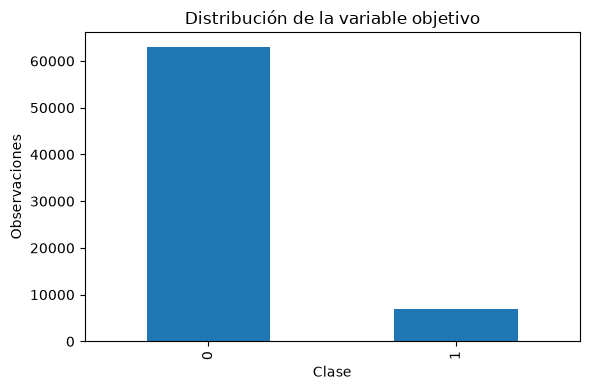

In [2]:
display(X.describe(include="all").T)
display(X.isna().sum().to_frame("faltantes"))

print("Edades negativas:", (X["edad_meses"] < 0).sum())
print("Edades mayores de 24 meses:", (X["edad_meses"] > 24).sum())

fig, ax = plt.subplots(figsize=(6, 4))
y.value_counts().sort_index().plot.bar(ax=ax)
ax.set_title("Distribución de la variable objetivo")
ax.set_xlabel("Clase")
ax.set_ylabel("Observaciones")
plt.tight_layout()
plt.show()


In [3]:
eda = X.copy()
eda["alerta"] = y.to_numpy()

for columna in ["sexo", "region", "nivel_educacion_madre"]:
    print("\n", columna)
    print(
        eda.groupby(columna)["alerta"]
        .agg(n="size", tasa_alerta="mean")
        .round(4)
    )



 sexo
          n  tasa_alerta
sexo                    
F     35185       0.1004
M     34815       0.0999

 region
              n  tasa_alerta
region                      
Amazonía  17606       0.0181
Costa     17534       0.1251
Insular   17497       0.1284
Sierra    17363       0.1296

 nivel_educacion_madre
                           n  tasa_alerta
nivel_educacion_madre                    
Primaria               24584       0.1059
Secundaria             31488       0.1052
Sin escolaridad         3437       0.0009
Superior               10491       0.1038


## 2. Preparación y prevención de fuga de información

La imputación y la codificación se ajustan **solo**
con los datos de entrenamiento gracias a `Pipeline`.


In [4]:
NUMERICAS = ["edad_meses", "peso_kg", "talla_cm"]
CATEGORICAS = ["sexo", "region", "nivel_educacion_madre"]

def preparar():
    return ColumnTransformer([
        ("num", Pipeline([
            ("imputar", SimpleImputer(
                strategy="median", add_indicator=True
            )),
            ("escalar", StandardScaler())
        ]), NUMERICAS),
        ("cat", Pipeline([
            ("imputar", SimpleImputer(strategy="most_frequent")),
            ("codificar", OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ))
        ]), CATEGORICAS)
    ])

X_fit, X_val, y_fit, y_val = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Entrenamiento:", X_fit.shape)
print("Validación:", X_val.shape)


Entrenamiento: (56000, 6)
Validación: (14000, 6)


## 3. Modelos y evaluación

La elección debe considerar principalmente **accuracy**.

Se incluyen métricas adicionales para identificar si un modelo
ignora completamente la clase minoritaria.


In [5]:
configuraciones = {
    "Dummy": DummyClassifier(strategy="most_frequent"),
    "Regresión logística": LogisticRegression(max_iter=2000),
    "Random Forest": RandomForestClassifier(
        n_estimators=120,
        max_depth=12,
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=42
    ),
    "Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.08,
        max_leaf_nodes=31,
        random_state=42
    )
}

resultados = []
matrices = {}

for nombre, clasificador in configuraciones.items():
    modelo = Pipeline([
        ("preprocesamiento", preparar()),
        ("modelo", clasificador)
    ])

    modelo.fit(X_fit, y_fit)
    pred = modelo.predict(X_val)
    prob = modelo.predict_proba(X_val)[:, 1]

    resultados.append({
        "modelo": nombre,
        "accuracy": accuracy_score(y_val, pred),
        "balanced_accuracy": balanced_accuracy_score(y_val, pred),
        "recall": recall_score(y_val, pred, zero_division=0),
        "f1": f1_score(y_val, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_val, prob),
        "positivos_predichos": int(pred.sum())
    })

    matrices[nombre] = confusion_matrix(
        y_val, pred, labels=[0, 1]
    )

resultados = pd.DataFrame(resultados).sort_values(
    ["accuracy", "roc_auc"], ascending=False
)

display(resultados.round(5))

print("Baseline clase mayoritaria:",
      round((y_val == 0).mean(), 6))
print("\nMatriz de confusión Random Forest:")
print(matrices["Random Forest"])


,modelo,accuracy,balanced_accuracy,recall,f1,roc_auc,positivos_predichos
1,Regresión logística,0.89986,0.5,0.0,0.0,0.65227,0
3,Gradient Boosting,0.89986,0.5,0.0,0.0,0.64561,0
2,Random Forest,0.89986,0.5,0.0,0.0,0.64548,0
0,Dummy,0.89986,0.5,0.0,0.0,0.50000,0


Baseline clase mayoritaria: 0.899857

Matriz de confusión Random Forest:
[[12598     0]
 [ 1402     0]]


## 4. Interpretación matemática

Para maximizar accuracy con costos de error iguales, la regla
bayesiana elige la clase de mayor probabilidad condicional.

Para Random Forest, la probabilidad positiva se obtiene
promediando las probabilidades estimadas por sus árboles:

$$
\hat p(x)=\frac{1}{B}\sum_{b=1}^{B}\hat p_b(x).
$$

La predicción positiva se produce cuando:

$$
\hat p(x)>0.5.
$$

En los experimentos realizados, los modelos de ensamble
obtuvieron cierta discriminación (ROC-AUC alrededor de 0.65),
pero no superaron el accuracy del baseline. Esto es compatible
con el fuerte desbalance y el mecanismo estocástico sintético.

**Limitación:** un buen accuracy con recall cero no constituye
un detector clínico útil de alertas de desnutrición.


## 4.1. Validación cruzada estratificada

Evaluamos las configuraciones utilizando tres particiones
estratificadas y exactamente las mismas métricas.

**La selección prioriza accuracy**, que es la métrica oficial
de la competencia. Recall y ROC-AUC se presentan para
documentar el efecto del desbalance.

La validación cruzada sirve para comparar modelos; no
constituye un conjunto de prueba independiente.

In [6]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=3, shuffle=True, random_state=2026
)

modelos_cv = {
    "Dummy": DummyClassifier(strategy="most_frequent"),
    "Random Forest": RandomForestClassifier(
        n_estimators=120, max_depth=12,
        min_samples_leaf=5, n_jobs=-1, random_state=42
    ),
    "Random Forest balanceado": RandomForestClassifier(
        n_estimators=120, max_depth=12,
        min_samples_leaf=5, class_weight="balanced",
        n_jobs=-1, random_state=42
    ),
    "Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=150, learning_rate=0.08,
        max_leaf_nodes=31, random_state=42
    )
}

filas_cv = []

for nombre, clasificador in modelos_cv.items():
    pipeline = Pipeline([
        ("preprocesamiento", preparar()),
        ("modelo", clasificador)
    ])

    scores = cross_validate(
        pipeline, X, y, cv=cv, n_jobs=1,
        scoring={
            "accuracy": "accuracy",
            "recall": "recall",
            "roc_auc": "roc_auc"
        },
        error_score="raise"
    )

    filas_cv.append({
        "modelo": nombre,
        "accuracy": scores["test_accuracy"].mean(),
        "accuracy_std": scores["test_accuracy"].std(),
        "recall": scores["test_recall"].mean(),
        "roc_auc": scores["test_roc_auc"].mean()
    })

tabla_cv = pd.DataFrame(filas_cv).sort_values(
    "accuracy", ascending=False
)

display(tabla_cv.round(5))
tabla_cv.to_csv(OUTPUT / "notebook_cv.csv", index=False)


,modelo,accuracy,accuracy_std,recall,roc_auc
0,Dummy,0.89987,0.00002,0.00000,0.50000
1,Random Forest,0.89987,0.00002,0.00000,0.65429
3,Gradient Boosting,0.89987,0.00002,0.00000,0.65474
2,Random Forest balanceado,0.45807,0.00616,0.85633,0.65305


## 4.2. Auditoría del umbral de clasificación

Para maximizar accuracy, una predicción positiva solo
conviene si su probabilidad condicional de pertenecer
a la clase 1 supera 0,5, suponiendo probabilidades
correctamente estimadas y costos iguales.

Estudiamos varios umbrales sobre la partición de
validación para comprobar si aumentar las predicciones
positivas produce más aciertos.

**Advertencia:** elegir un umbral después de observar
la validación puede sobreajustarlo. No se utiliza
este análisis para modificar las etiquetas ocultas
de Kaggle.

In [7]:
modelo_umbral = Pipeline([
    ("preprocesamiento", preparar()),
    ("modelo", RandomForestClassifier(
        n_estimators=120, max_depth=12,
        min_samples_leaf=5, n_jobs=-1, random_state=42
    ))
])

modelo_umbral.fit(X_fit, y_fit)
prob_val = modelo_umbral.predict_proba(X_val)[:, 1]

comparacion_umbrales = []

for u in [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]:
    pred_u = (prob_val >= u).astype(int)

    comparacion_umbrales.append({
        "umbral": u,
        "accuracy": accuracy_score(y_val, pred_u),
        "positivos_predichos": int(pred_u.sum()),
        "recall": recall_score(
            y_val, pred_u, zero_division=0
        )
    })

tabla_umbrales = pd.DataFrame(comparacion_umbrales)
baseline_accuracy = (y_val == 0).mean()

print("Accuracy baseline:", round(baseline_accuracy, 6))
display(tabla_umbrales.round(6))

tabla_umbrales.to_csv(
    OUTPUT / "notebook_umbrales.csv",
    index=False
)


Accuracy baseline: 0.899857


,umbral,accuracy,positivos_predichos,recall
0,0.10,0.428143,9180,0.918688
1,0.15,0.781214,2265,0.215407
2,0.20,0.891786,157,0.015692
3,0.25,0.899571,8,0.001427
4,0.30,0.899929,1,0.000713
5,0.40,0.899857,0,0.000000
6,0.50,0.899857,0,0.000000


## 5. Entrenamiento final y archivo para Kaggle

Se utiliza Random Forest como modelo final por su rendimiento
validado, estabilidad y facilidad de interpretación matemática.

Su accuracy empata con el baseline, por lo que no se afirma
una superioridad predictiva inexistente.


In [8]:
modelo_final = Pipeline([
    ("preprocesamiento", preparar()),
    ("modelo", RandomForestClassifier(
        n_estimators=120,
        max_depth=12,
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=42
    ))
])

modelo_final.fit(X, y)
pred_test = modelo_final.predict(X_test).astype(int)

submission = sample.copy()
submission["alerta_desnutricion"] = pred_test

assert submission["ID"].equals(sample["ID"])
assert submission["alerta_desnutricion"].isin([0, 1]).all()
assert not submission.isna().any().any()

ruta = OUTPUT / "submission.csv"
submission.to_csv(ruta, index=False)

print("Archivo:", ruta)
print("Filas:", len(submission))
print("Predicciones:")
print(submission["alerta_desnutricion"].value_counts())
display(submission.head())


Archivo: outputs\submission.csv
Filas: 30000
Predicciones:
alerta_desnutricion
0    30000
Name: count, dtype: int64


,ID,alerta_desnutricion
0,1,0
1,2,0
2,3,0
3,4,0
4,5,0


## 6. Conclusiones

1. El conjunto presenta un desbalance cercano al 90/10.
2. Se estableció un baseline explícito para accuracy.
3. Se compararon cuatro modelos con el mismo protocolo.
4. El modelo final no demostró una mejora en accuracy frente al baseline.
5. El resultado debe interpretarse junto al recall de la clase positiva.
6. Las predicciones se generan sin usar etiquetas del conjunto de prueba.

**Experimentos adicionales realizados en el proyecto:**
validación cruzada, CatBoost, LightGBM, Extra Trees,
MLP, modelo beta-binomial, Probit y análisis de umbrales.
